# Can ENSO indicators improve agricultural commodity price and risk forecasting?

1. Data · 2. Descriptive analysis · 3. Baselines · 4. ML with/without climate · 5. Evaluation · 6. Robustness · 7. Conclusion

## Step 1 — Data

- **Prices**: World Bank Pink Sheet, monthly averages, from 1960, downloaded automatically below.
  Main study: wheat, maize, soybeans. Extra commodities found in the literature to be ENSO-sensitive:
  vegetable oils, cocoa, coffee, sugar, rice, cotton.
  (Fish meal, rapeseed and sunflower oil are left out: they start in 1979 or later.)
  If the download link stops working (the World Bank changes it about once a year), get the new "Monthly prices" link from
  https://www.worldbank.org/en/research/commodity-markets
- **Climate**: NOAA ONI (3-month average of the Niño 3.4 sea temperature anomaly), saved as `data/oni.ascii.txt`
  (from https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt).
  We use the official ONI because it removes the warming trend of the ocean.

In [143]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skfin.plot import line, heatmap

In [144]:
# Download the World Bank price file into the data/ folder (only the first time)
PRICE_URL = "https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/CMO-Historical-Data-Monthly.xlsx"
if not os.path.exists("data/CMO-Historical-Data-Monthly.xlsx"):
    os.makedirs("data", exist_ok=True)
    !curl -sL -o data/CMO-Historical-Data-Monthly.xlsx {PRICE_URL}

In [145]:
# Prices: commodity names are on Excel row 5, units on row 6 (skipped)
prices = pd.read_excel("data/CMO-Historical-Data-Monthly.xlsx", sheet_name="Monthly Prices",
                       header=4, skiprows=[5], index_col=0)

commodities = ["Wheat, US HRW", "Maize", "Soybeans",
               "Palm oil", "Soybean oil", "Coconut oil",
               "Cocoa", "Coffee, Arabica", "Coffee, Robusta",
               "Sugar, world", "Rice, Thai 5% ", "Cotton, A Index"]
prices = prices[commodities]
prices.index = pd.to_datetime(prices.index, format="%YM%m") + pd.offsets.MonthEnd(0)

returns = np.log(prices.astype(float)).diff()

In [146]:
# ONI: one row per month, starting with DJF 1950 (centred on January 1950)
oni = pd.read_csv("data/oni.ascii.txt", sep=r"\s+")
oni.index = pd.date_range("1950-01-31", periods=len(oni), freq="ME")
oni = oni["ANOM"]

**No look-ahead.** A row dated *t* only contains what is known at the end of month *t*;
it will be used to predict the return of month *t+1*.
The ONI centred on month *m* uses month *m+1*, which is published at the start of *m+2* → we shift ONI by 2 months.

**ENSO phase** (NOAA rule): El Niño if ONI ≥ 0.5, La Niña if ONI ≤ −0.5, otherwise Neutral.

In [147]:
data = returns.copy()
data["oni"] = oni
data["oni"] = data["oni"].shift(2)   # shift inside our table, so the last months are kept

data["phase"] = "Neutral"
data.loc[data["oni"] >= 0.5, "phase"] = "El Nino"
data.loc[data["oni"] <= -0.5, "phase"] = "La Nina"

data = data.dropna()
data.to_csv("data/enso_commodities.csv")

print(data.index[0].date(), "to", data.index[-1].date(), "-", len(data), "months")
data.tail()

1960-03-31 to 2026-10-31 - 800 months


,"Wheat, US HRW",Maize,Soybeans,Palm oil,Soybean oil,Coconut oil,Cocoa,"Coffee, Arabica","Coffee, Robusta","Sugar, world","Rice, Thai 5%","Cotton, A Index",oni,phase
2026-06-30,-0.057741,-0.092493,-0.019211,-0.022512,-0.023290,-0.093057,0.056089,-0.023291,0.016217,-0.060625,0.115761,-0.066182,0.46,Neutral
2026-07-31,0.080580,0.079457,0.029726,-0.007912,-0.048273,-0.028185,0.242946,0.152677,0.087235,0.060625,-0.056206,0.031091,0.95,El Nino
2026-08-31,0.062520,0.048478,0.008333,-0.000883,-0.011526,0.029195,0.058841,0.007557,-0.022361,0.111226,0.008529,0.073743,1.39,El Nino
2026-09-30,0.050232,0.067325,0.083548,0.041528,-0.014751,0.048285,-0.005055,-0.093305,-0.075655,0.075986,0.023086,-0.004751,1.80,El Nino
2026-10-31,-0.090423,-0.056226,-0.017325,-0.052186,-0.043664,-0.024344,-0.029137,0.019100,-0.016394,0.047628,0.014418,-0.048790,2.16,El Nino


**Sample period.** Before ~1973 grain prices were partly administered (US price supports, fixed exchange rates):
many months show no price change at all and volatility is much lower.
We keep the data from 1960 so models can **learn** from early ENSO events,
but we only **evaluate** forecasts from 1980 onwards. Robustness check later: start the whole sample in 1973.

In [148]:
START_EVAL = "1980-01-01"   # first month used to evaluate the models

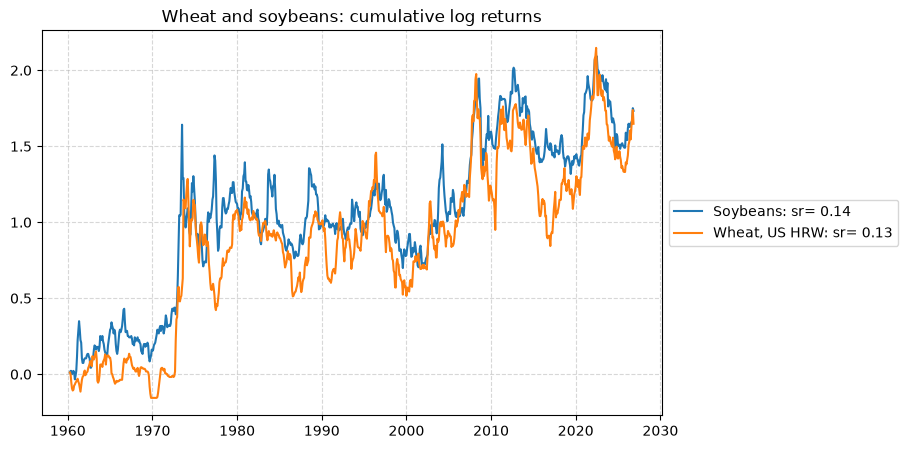

In [149]:
line(data[["Wheat, US HRW", "Soybeans"]], cumsum=True, title="Wheat and soybeans: cumulative log returns")

## Step 2 — Descriptive analysis

Before any model, we look at the raw link between ENSO and prices:
what is the average return of each commodity in each ENSO phase?

phase,La Nina,Neutral,El Nino
"Wheat, US HRW",0.07,0.04,-0.05
Maize,0.12,-0.05,0.08
Soybeans,0.02,-0.02,0.12
Palm oil,-0.05,0.02,0.11
Soybean oil,0.01,0.01,0.09
Coconut oil,-0.08,0.00,0.18
Cocoa,-0.02,-0.01,0.18
"Coffee, Arabica",-0.02,0.05,0.04
"Coffee, Robusta",-0.04,0.03,0.08
"Sugar, world",0.04,-0.03,0.13


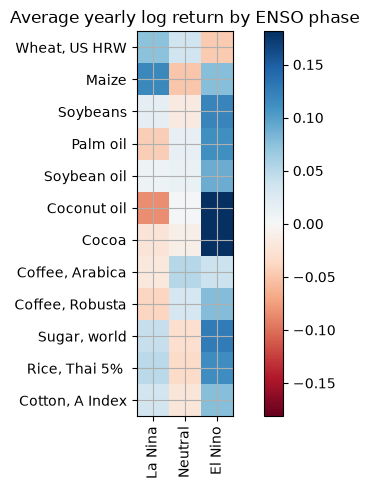

In [150]:
# Average return per year of each commodity in each ENSO phase (blue = prices rise, red = prices fall)
by_phase = data.groupby("phase")[commodities].mean() * 12
by_phase = by_phase.loc[["La Nina", "Neutral", "El Nino"]]

heatmap(by_phase, title="Average yearly log return by ENSO phase")
by_phase.T.round(2)

**Reading.** Most commodities rise during El Niño months, most strongly the tropical ones
(coconut oil, cocoa, palm oil, sugar), as in Ubilava (2018). Wheat goes the other way: it falls in El Niño and rises in La Niña.
These are simple averages over the whole sample, not forecasts, and each phase contains only a few independent episodes.

phase,La Nina,Neutral,El Nino
"Wheat, US HRW",0.09,0.04,-0.12
Maize,0.17,-0.08,0.04
Soybeans,0.07,-0.02,0.03
Palm oil,-0.06,0.03,0.05
Soybean oil,0.01,0.03,0.01
Coconut oil,-0.10,0.01,0.15
Cocoa,-0.03,-0.04,0.15
"Coffee, Arabica",-0.09,0.08,-0.02
"Coffee, Robusta",-0.10,0.03,0.03
"Sugar, world",0.08,-0.05,0.04


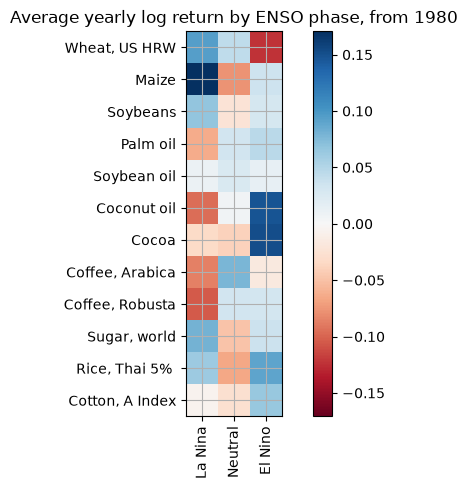

In [151]:
# Same table on the evaluation period only (from 1980), to leave out the 1970s commodity boom
by_phase_1980 = data[START_EVAL:].groupby("phase")[commodities].mean() * 12
by_phase_1980 = by_phase_1980.loc[["La Nina", "Neutral", "El Nino"]]

heatmap(by_phase_1980, title="Average yearly log return by ENSO phase, from 1980")
by_phase_1980.T.round(2)

**Reading.** Without the 1970s, the El Niño effect stays for coconut oil, cocoa and rice, and wheat still falls in El Niño.
But it almost disappears for soybeans, palm oil and sugar: their full-sample result came mostly from the 1972–73 boom,
when all commodity prices rose together.

## Step 3 — Base model (no climate)

Our base model uses prices only. It is the momentum backtest of the skfin course (notebook 11), applied to our 12 commodities:

- **Predictor**: the average return of each commodity over the past 12 months.
- **Positions**: each month, buy the commodities with the best past returns and sell the worst ones (`MeanVariance`, total position = 0).
- **No look-ahead**: positions decided at the end of month *t* earn the return of month *t+1* (`Backtester` does this shift).

The models with ENSO will have to beat this.

In [152]:
from skfin.backtesting import Backtester
from skfin.estimators.mean_variance import MeanVariance

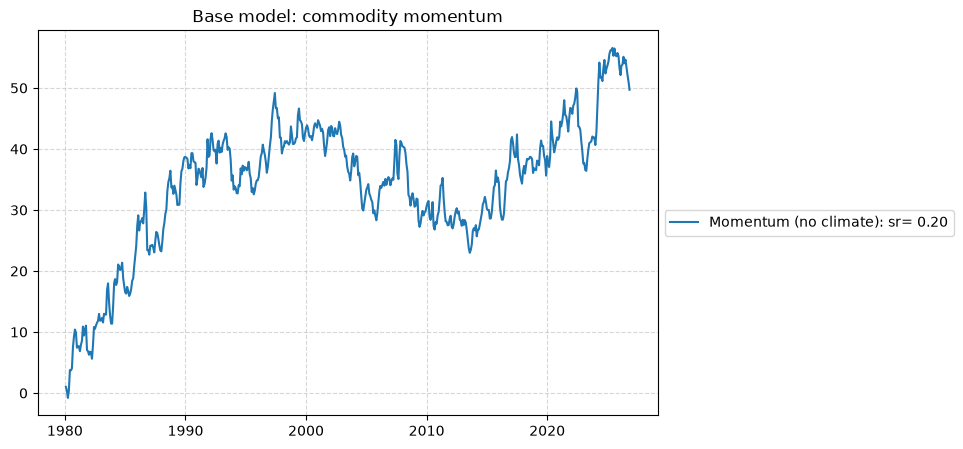

In [153]:
# Predictor: average return of each commodity over the past 12 months (momentum)
ret = data[commodities]
X = ret.rolling(12).mean()
y = ret.shift(-1)   # target = next month's return

# Each month: buy past winners, sell past losers (MeanVariance), trained on the past 36 months
m = Backtester(estimator=MeanVariance(), start_date=START_EVAL, name="Momentum (no climate)")
pnl_momentum = m.train(X, y, ret)

line(pnl_momentum, cumsum=True, title="Base model: commodity momentum")

**Reading.** Momentum alone is weak: Sharpe ratio of about 0.2 from 1980. This is the bar for the climate models.

Caution: World Bank prices are monthly *averages*, which makes a return look a bit like the previous month's return
(correlation of 0.2 to 0.5). Part of this small profit comes from that effect, so it could not be fully earned by a real trader.

## Step 4 — Ridge with and without climate

We now let a model learn the forecast, as in skfin notebook 15: a `Ridge` regression predicts next month's returns,
then `MeanVariance` turns the forecast into positions.

We run it twice, with one difference only:

- **prices only**: the 12-month average returns of the 12 commodities;
- **prices + ONI**: the same table plus the ONI column.

If ENSO adds information, the second line should end above the first.
We train on the past 120 months instead of 36, because 3 years often contain no ENSO event at all.
Momentum is re-run with the same window so that the three lines are comparable.

In [154]:
from skfin.estimators.linear import Ridge
from skfin.plot import bar
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

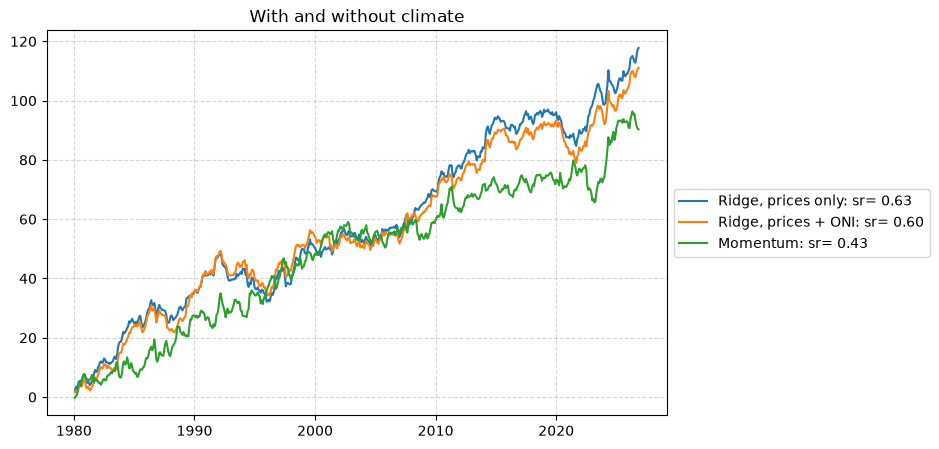

In [155]:
WINDOW = 120   # months of past data used for training (10 years, to cover several ENSO events)

# Two feature tables: prices only, and prices + ONI
X_price = ret.rolling(12).mean()
X_climate = X_price.copy()
X_climate["oni"] = data["oni"]

# Same model for both: Ridge predicts next month's returns, MeanVariance turns the forecast into positions
estimator = make_pipeline(StandardScaler(with_mean=False), Ridge(), MeanVariance())

m_momentum = Backtester(MeanVariance(), max_train_size=WINDOW, start_date=START_EVAL)
m_price = Backtester(estimator, max_train_size=WINDOW, start_date=START_EVAL)
m_climate = Backtester(estimator, max_train_size=WINDOW, start_date=START_EVAL)

pnls = {
    "Momentum": m_momentum.train(X_price, y, ret),
    "Ridge, prices only": m_price.train(X_price, y, ret),
    "Ridge, prices + ONI": m_climate.train(X_climate, y, ret),
}
line(pnls, cumsum=True, title="With and without climate")

**Reading.** Ridge does better than momentum (Sharpe ratio 0.63 against 0.43), but adding ONI does not help: 0.60 with ONI, 0.63 without.
The two Ridge lines are almost the same strategy (correlation 0.92).

One reason: positions sum to zero, so the strategy only bets on *differences* between commodities.
El Niño pushes most of them up together, and that common move is cancelled out.

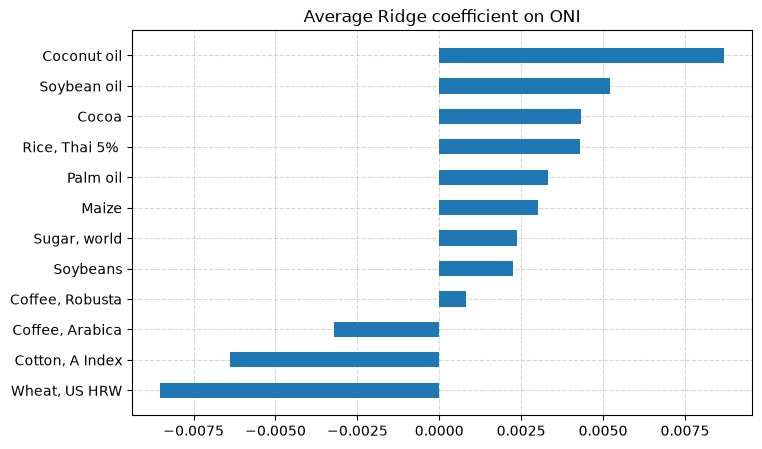

In [156]:
# What did the model learn? Average Ridge coefficient on ONI for each commodity
# (ONI is the last feature column; one Ridge model is fitted each month)
coef_oni = [m.named_steps["ridge"].coef_[:, -1] for m in m_climate.estimators_]
coef_oni = pd.DataFrame(coef_oni, columns=commodities, index=m_climate.h_.index)

bar(coef_oni.mean(), horizontal=True, title="Average Ridge coefficient on ONI")

**Reading.** The model did learn the pattern of Step 2: a positive coefficient for coconut oil, cocoa, rice and the vegetable oils,
and a negative one for wheat. So ONI is not ignored. Its effect is real but too small to improve this strategy.

## Step 5 — One commodity at a time

In Step 4 positions summed to zero, so an El Niño that lifts most commodities together was cancelled out.
Here we test each commodity on its own, as skfin notebook 41 does for the stock market:
does ONI help predict whether *this* commodity will go up or down next month?

For each commodity we run two backtests: its own 12-month average return alone, then the same plus ONI.
(This cell runs 24 backtests and takes about a minute.)

In [ ]:
from skfin.estimators.mean_variance import TimingMeanVariance
from skfin.metrics import sharpe_ratio

In [ ]:
# Ridge predicts next month's return of ONE commodity, TimingMeanVariance turns the forecast
# into a position: buy if the forecast is positive, sell if negative (with a size limit)
timing = make_pipeline(StandardScaler(), Ridge(), TimingMeanVariance(a_min=-0.25, a_max=0.25))

pnl_price = {}
pnl_climate = {}
for c in commodities:
    r = ret[c]
    target = r.shift(-1)
    f_price = r.rolling(12).mean().to_frame()   # the commodity's own 12-month average return
    f_climate = f_price.copy()
    f_climate["oni"] = data["oni"]

    pnl_price[c] = Backtester(timing, max_train_size=WINDOW, start_date=START_EVAL).train(f_price, target, r)
    pnl_climate[c] = Backtester(timing, max_train_size=WINDOW, start_date=START_EVAL).train(f_climate, target, r)

pnl_price = pd.DataFrame(pnl_price)
pnl_climate = pd.DataFrame(pnl_climate)

In [ ]:
# Sharpe ratio of each commodity, without and with ONI
sr = pd.DataFrame({"Prices only": pnl_price.apply(sharpe_ratio),
                   "Prices + ONI": pnl_climate.apply(sharpe_ratio)})

bar(sr, horizontal=True, title="Sharpe ratio by commodity, with and without ONI")
sr.round(2)

**Reading.** Adding ONI raises the Sharpe ratio for 9 of the 12 commodities.
The largest gains are for maize, wheat, soybeans and palm oil; coconut oil is the best in both versions.
Coffee, sugar and cotton do not benefit. Each number is small on its own: no single commodity gives a strong strategy.

In [ ]:
# All commodities together: average pnl of the 12 single-commodity strategies
line({"Prices only": pnl_price.mean(axis=1), "Prices + ONI": pnl_climate.mean(axis=1)},
     cumsum=True, title="Average of the 12 commodities, with and without ONI")

**Reading.** Averaged over the 12 commodities, the Sharpe ratio goes from 0.19 without ONI to 0.46 with ONI.
But most of the gap opens between 1983 and 1992; after that the two lines move almost in parallel.

In [ ]:
# Honesty check: is the gain from ONI (Sharpe with ONI minus Sharpe without) there in both halves?
gain = pd.DataFrame({
    "1980-2002": pnl_climate[:"2002"].apply(sharpe_ratio) - pnl_price[:"2002"].apply(sharpe_ratio),
    "2003-2026": pnl_climate["2003":].apply(sharpe_ratio) - pnl_price["2003":].apply(sharpe_ratio),
})
bar(gain, horizontal=True, title="Gain in Sharpe ratio from adding ONI, by half")

**Reading.** The gain is not stable over time. It holds in both halves for maize, coconut oil, soybeans and cocoa,
and wheat gains mostly in the second half. For palm oil, rice and soybean oil it is there in 1980–2002 and gone afterwards.
Overall the average goes from 0.35 to 0.80 in the first half, but only from 0.11 to 0.21 in the second.

So ENSO did add forecasting power for single commodities, mostly before the early 2000s, and much less since —
in line with Ubilava (2018), who finds that the ENSO effect on prices has weakened over time.

## Step 6 — Boosted trees

Ridge can only learn a straight-line effect: twice the ONI, twice the effect, and La Niña is the exact opposite of El Niño.
Boosted trees (LightGBM, as in skfin notebook 16) can learn other shapes, for example an effect only when ONI is strongly positive.

We repeat the test of Step 5, one commodity at a time, with and without ONI.
(This cell takes about one to two minutes.)

In [ ]:
from skfin.estimators import MultiLGBMRegressor

In [ ]:
# Same test as Step 5, with boosted trees instead of Ridge (same settings as skfin notebook 16)
boosting = make_pipeline(MultiLGBMRegressor(min_child_samples=5, n_estimators=25),
                         TimingMeanVariance(a_min=-0.25, a_max=0.25))

pnl_price_gb = {}
pnl_climate_gb = {}
for c in commodities:
    r = ret[[c]]   # one-column table (MultiLGBMRegressor needs a table, not a single series)
    target = r.shift(-1)
    f_price = r.rolling(12).mean()
    f_climate = f_price.copy()
    f_climate["oni"] = data["oni"]

    pnl_price_gb[c] = Backtester(boosting, max_train_size=WINDOW, start_date=START_EVAL).train(f_price, target, r)
    pnl_climate_gb[c] = Backtester(boosting, max_train_size=WINDOW, start_date=START_EVAL).train(f_climate, target, r)

pnl_price_gb = pd.DataFrame(pnl_price_gb)
pnl_climate_gb = pd.DataFrame(pnl_climate_gb)

In [ ]:
# Ridge and boosting, with and without ONI: average pnl of the 12 single-commodity strategies
line({"Ridge, prices only": pnl_price.mean(axis=1),
      "Ridge, prices + ONI": pnl_climate.mean(axis=1),
      "Boosting, prices only": pnl_price_gb.mean(axis=1),
      "Boosting, prices + ONI": pnl_climate_gb.mean(axis=1)},
     cumsum=True, title="Ridge and boosting, with and without ONI")

**Reading.** Boosting gives the same answer as Ridge. Without ONI it is close to zero (Sharpe ratio 0.09);
with ONI it reaches 0.56, a little above Ridge with ONI (0.46).
Again almost all of the gain comes before the early 2000s: from 0.18 to 1.06 in 1980–2002, but only from 0.03 to 0.13 in 2003–2026.

In [ ]:
# Sharpe ratio of each commodity with boosting, without and with ONI
sr_gb = pd.DataFrame({"Prices only": pnl_price_gb.apply(sharpe_ratio),
                      "Prices + ONI": pnl_climate_gb.apply(sharpe_ratio)})

bar(sr_gb, horizontal=True, title="Boosting: Sharpe ratio by commodity, with and without ONI")
sr_gb.round(2)

**Reading.** ONI helps for 9 of the 12 commodities, but not exactly the same ones as with Ridge:
the largest gains are now for palm oil, cotton, robusta coffee and soybean oil, while wheat and soybeans stay negative.
The overall conclusion (ONI helps on average) is stable across the two models; the ranking of single commodities is not.